# Cat and Dog Facial Feature Classification 

In [1]:
#This cell finds the training labels CSV file in the attached competition data and displays its location
from pathlib import Path

label_files = list(Path("/kaggle/input").rglob("train_labels.csv"))

print("Training label files found:", len(label_files))
for path in label_files:
    print(path)
    

Training label files found: 1
/kaggle/input/datasets/nkw3744/cat-and-dog-facial-feature-classification/train_labels.csv


In [2]:
# Load the training labels, preserve leading zeros in image IDs, and display the first five rows.
import pandas as pd

labels_path = label_files[0]
labels = pd.read_csv(labels_path, dtype={"image_id": str})

print("Number of labelled images:", len(labels))
display(labels.head())

Number of labelled images: 63660


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [3]:
# Check that every training label has a matching JPG image.
data_dir = labels_path.parent
first_filename = labels["image_id"].iloc[0] + ".jpg"

train_folders = [
    folder for folder in data_dir.rglob("train")
    if folder.is_dir() and (folder / first_filename).is_file()
]

if len(train_folders) != 1:
    raise ValueError("Could not identify one training image folder.")

train_dir = train_folders[0]
image_paths = labels["image_id"].map(
    lambda image_id: train_dir / f"{image_id}.jpg"
)
missing_images = image_paths.map(lambda path: not path.is_file())

print("Training images checked:", len(image_paths))
print("Missing training images:", missing_images.sum())

Training images checked: 63660
Missing training images: 0


In [4]:
# Count the training images in each class.
class_counts = labels["class"].value_counts().sort_index()

print("Training images per class:")
display(class_counts.rename("image_count").to_frame())

Training images per class:


,image_count
class,
CatEye,13884
CatFace,6942
CatMouth,6942
CatNose,6942
DogEye,11580
DogFace,5790
DogMouth,5790
DogNose,5790


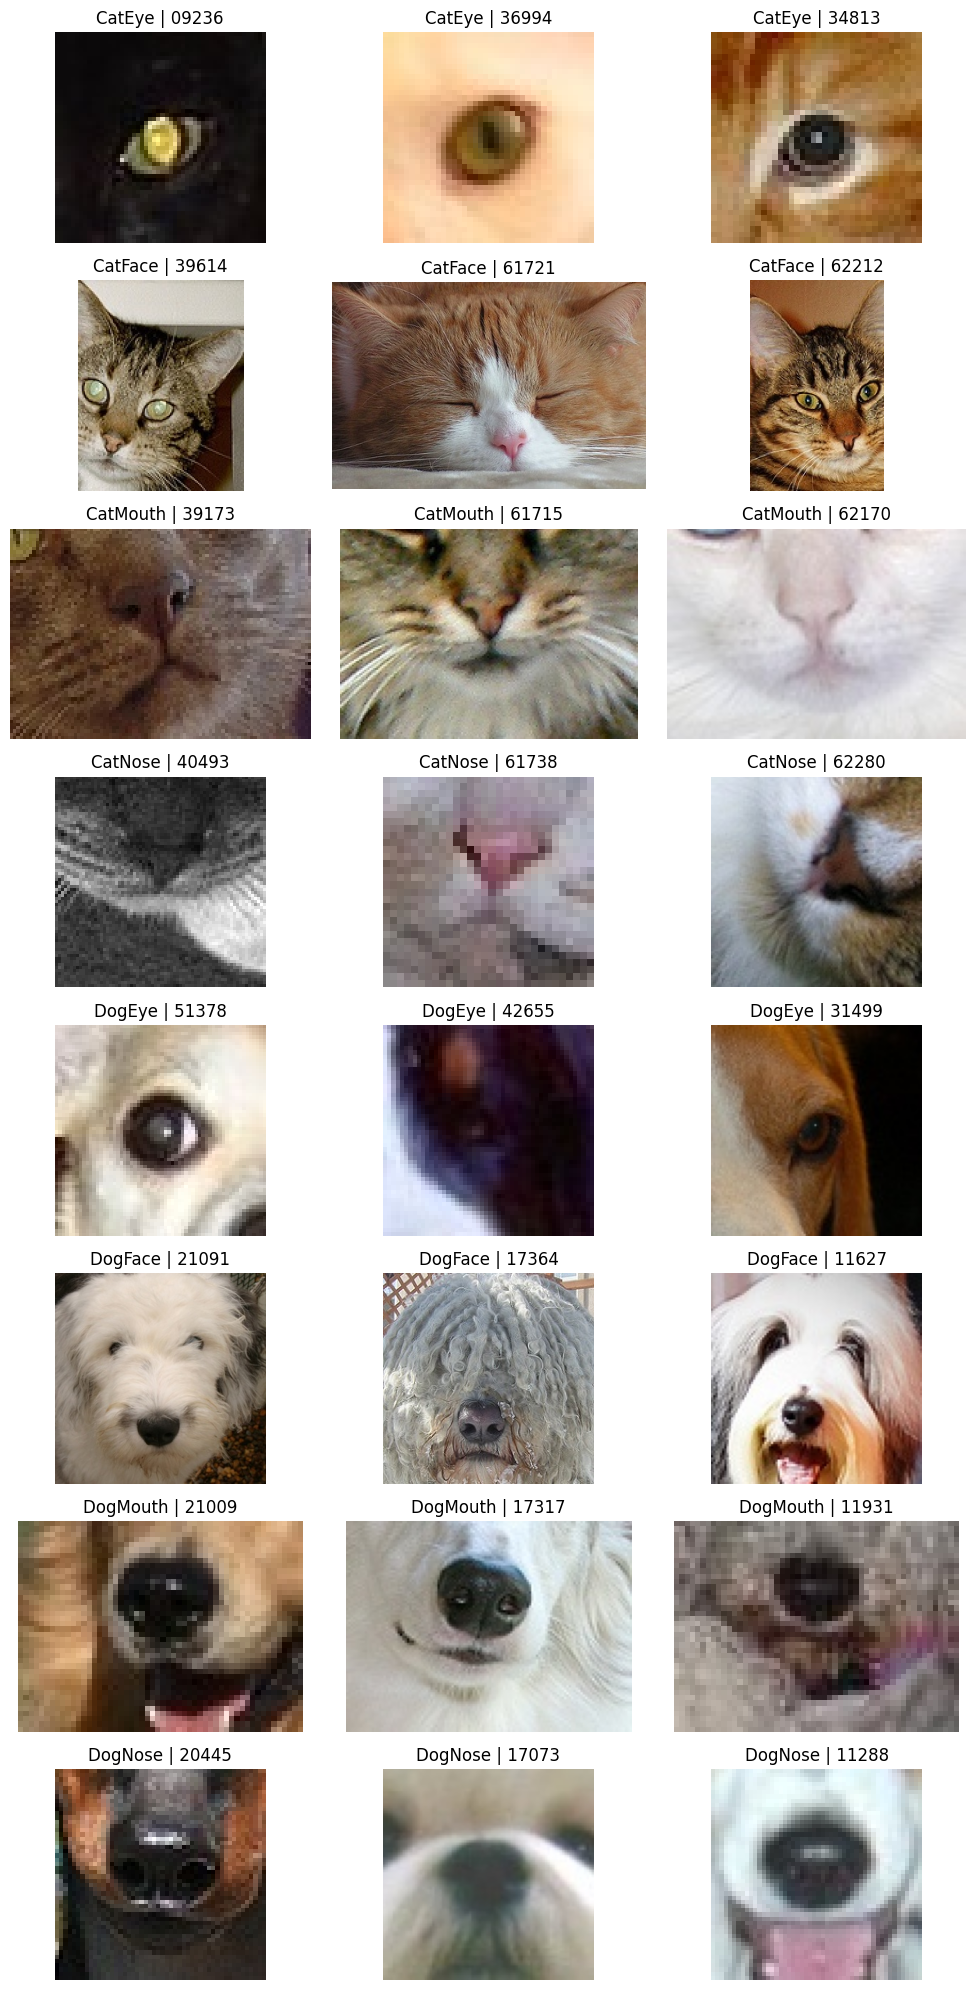

In [5]:
# Display three randomly selected training images from each class.
import matplotlib.pyplot as plt
from PIL import Image

class_names = sorted(labels["class"].unique())
fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 20))

for row, class_name in enumerate(class_names):
    examples = labels.loc[
        labels["class"] == class_name
    ].sample(n=3, random_state=42)

    for col, image_id in enumerate(examples["image_id"]):
        image_path = train_dir / f"{image_id}.jpg"

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(f"{class_name} | {image_id}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Check training image sizes and record any images that cannot be fully read.
from tqdm.auto import tqdm

image_records = []
unreadable_images = []

for image_id, image_path in tqdm(
    zip(labels["image_id"], image_paths),
    total=len(labels),
    desc="Checking training images"
):
    try:
        with Image.open(image_path) as image:
            image.load()
            image_records.append({
                "image_id": image_id,
                "width": image.width,
                "height": image.height,
                "mode": image.mode
            })
    except (OSError, ValueError) as error:
        unreadable_images.append({
            "image_id": image_id,
            "error": str(error)
        })

image_info = pd.DataFrame(image_records)
unreadable_info = pd.DataFrame(
    unreadable_images, columns=["image_id", "error"]
)

print("Successfully read:", len(image_info))
print("Unreadable images:", len(unreadable_info))
display(image_info[["width", "height"]].describe())
display(image_info["mode"].value_counts())

if not unreadable_info.empty:
    display(unreadable_info)

Checking training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Successfully read: 63660
Unreadable images: 0


,width,height
count,63660.000000,63660.000000
mean,113.095209,109.737857
std,98.491801,101.911146
min,4.000000,4.000000
25%,54.000000,50.000000
50%,84.000000,80.000000
75%,138.000000,130.000000
max,2219.000000,2219.000000


mode
RGB    63660
Name: count, dtype: int64

In [7]:
# Hash training image pixels to identify exact duplicates and conflicting labels.
import hashlib

image_hashes = []

for image_path in tqdm(image_paths, desc="Checking exact duplicates"):
    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        fingerprint = hashlib.sha256()
        fingerprint.update(f"{rgb.width},{rgb.height}:".encode())
        fingerprint.update(rgb.tobytes())
        image_hashes.append(fingerprint.hexdigest())

labels["image_hash"] = image_hashes

hash_groups = labels.groupby("image_hash").agg(
    image_count=("image_id", "size"),
    class_count=("class", "nunique")
)

duplicate_groups = hash_groups[hash_groups["image_count"] > 1]
conflicting_groups = hash_groups[hash_groups["class_count"] > 1]

print("Exact duplicate groups:", len(duplicate_groups))
print("Images in duplicate groups:", duplicate_groups["image_count"].sum())
print("Extra copies:", (duplicate_groups["image_count"] - 1).sum())
print("Groups with conflicting class labels:", len(conflicting_groups))

Checking exact duplicates:   0%|          | 0/63660 [00:00<?, ?it/s]

Exact duplicate groups: 15
Images in duplicate groups: 30
Extra copies: 15
Groups with conflicting class labels: 0


In [8]:
# Create a new training-label table that keeps the first copy of each identical image and leaves out any extra copies, without deleting image files.
clean_labels = labels.drop_duplicates(
    subset="image_hash", keep="first"
).copy().reset_index(drop=True)

print("Original rows:", len(labels))
print("Extra copies excluded:", len(labels) - len(clean_labels))
print("Remaining rows:", len(clean_labels))

assert clean_labels["image_hash"].is_unique

Original rows: 63660
Extra copies excluded: 15
Remaining rows: 63645


In [9]:
# Split the cleaned labels into 80% for learning and 20% for validation.
from sklearn.model_selection import train_test_split

train_labels, val_labels = train_test_split(
    clean_labels,
    test_size=0.20,  # Hold back 20% of the images for validation.
    random_state=42,  # Repeat the same split when using the same input data.
    stratify=clean_labels["class"]  # Keep similar class proportions in both groups.
)

# Give each table a fresh row index starting at zero.
train_labels = train_labels.reset_index(drop=True)
val_labels = val_labels.reset_index(drop=True)

# Stop with an error if an identical image fingerprint appears in both groups.
assert set(train_labels["image_hash"]).isdisjoint(val_labels["image_hash"])

print("Training images:", len(train_labels))
print("Validation images:", len(val_labels))

# Display the number of images from each class in each group.
display(pd.DataFrame({
    "training": train_labels["class"].value_counts(),
    "validation": val_labels["class"].value_counts()
}).sort_index())

Training images: 50916
Validation images: 12729


,training,validation
class,,
CatEye,11102,2775
CatFace,5553,1389
CatMouth,5553,1388
CatNose,5553,1388
DogEye,9261,2315
DogFace,4630,1158
DogMouth,4632,1158
DogNose,4632,1158


In [10]:
# Save the training and validation lists so we can reuse the same split later.
output_dir = Path("/kaggle/working/splits")
output_dir.mkdir(parents=True, exist_ok=True)

train_labels.to_csv(output_dir / "train_labels.csv", index=False)
val_labels.to_csv(output_dir / "val_labels.csv", index=False)

# Read image IDs back as text to preserve their leading zeros.
saved_train = pd.read_csv(
    output_dir / "train_labels.csv", dtype={"image_id": str}
)
saved_val = pd.read_csv(
    output_dir / "val_labels.csv", dtype={"image_id": str}
)

# Check that the saved files contain the same rows and values as our tables.
pd.testing.assert_frame_equal(saved_train, train_labels)
pd.testing.assert_frame_equal(saved_val, val_labels)

print("Saved and verified training rows:", len(saved_train))
print("Saved and verified validation rows:", len(saved_val))
print("Saved in:", output_dir)

Saved and verified training rows: 50916
Saved and verified validation rows: 12729
Saved in: /kaggle/working/splits
